# Example 3.3: Variability between AG Runs
**Chapter 3 · Four Bar Mechanisms with Genetic Algorithms**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Run 8 independent runs of the GA (different seeds) to minimize $f(x)=(x-3.7)^2+0.5\,\sin(5x)$. Report the mean, standard deviation, and P10–P90 interval of the error and display the distribution of solutions.

**Objective:** Quantify the stochastic variability of the GA and distinguish between run-to-run variability and solution accuracy.

In [3]:
# ── Imports─────────────────────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

In [4]:
# ── Objective function ──────────────────────────────────────────────────────
def f_obj(x):
    return (x - 3.7)**2 + 0.5 * sin(5 * x)

def ga_run(seed, n_pop=25, n_gen=50, pm=0.08):
    """A single complete run of the GA; returns the best x found."""
    rng = random.default_rng(seed)
    pop = rng.uniform(0, 10, n_pop)
    for _ in range(n_gen):
        fit = array([f_obj(x) for x in pop])
        idx = argsort(fit)[:n_pop // 2]
        elite = pop[idx]
        hijos = []
        for i in range(0, len(elite) - 1, 2):
            a = rng.uniform(0, 1)
            hijos += [a*elite[i]+(1-a)*elite[i+1],
                       (1-a)*elite[i]+a*elite[i+1]]
        pop = clip(array(hijos[:n_pop] if hijos else elite), 0, 10)
        mask = rng.random(len(pop)) < pm
        pop[mask] += rng.normal(0, 0.3, mask.sum())
        pop = clip(pop, 0, 10)
    return pop[argmin(array([f_obj(x) for x in pop]))]

# ── Experiment: 8 runs ───────────────────────────────────────────────
N_RUNS = 8
semillas = arange(N_RUNS)
soluciones = array([ga_run(s) for s in semillas])
errores    = abs(soluciones - 3.4893)   # reference minimum

print(f"Solutions per run: {around(soluciones, 4)}")
print(f"Mean      : {mean(soluciones):.4f}")
print(f"Std dev   : {std(soluciones):.4f}")
print(f"Mean error: {mean(errores):.4f}")
print(f"Max error : {max(errores):.4f}")
p10, p90 = percentile(errores, [10, 90])
print(f"P10–P90 error interval: [{p10:.4f}, {p90:.4f}]")



Solutions per run: [3.4797 3.4901 3.4846 3.4908 3.4953 3.4893 3.512  3.4897]
Mean      : 3.4915
Std dev   : 0.0089
Mean error: 0.0057
Max error : 0.0227
P10–P90 error interval: [0.0003, 0.0136]


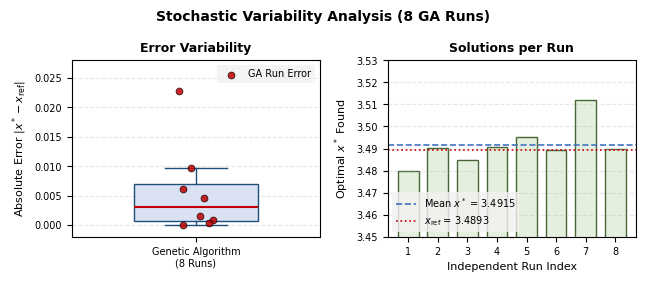

In [6]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# 1. Automated Filename Determination
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "3.3_run_variability"
except Exception:
    notebook_name = "3.3_run_variability"

# 2. Configure Springer-compatible Plot Parameters
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 9,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7
})

# 3. Create Figure (horizontal subplot layout conforming to column-width standards)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.5, 2.8))

# Left Subplot: Boxplot showing Error Variability
bp = ax1.boxplot(errores, positions=[1], patch_artist=True, widths=0.4,
                 showfliers=False, # We plot individual points to avoid redundancy
                 boxprops=dict(facecolor='#D9E1F2', color='#1F4E79', linewidth=1),
                 capprops=dict(color='#1F4E79', linewidth=1),
                 whiskerprops=dict(color='#1F4E79', linewidth=1),
                 medianprops=dict(color='#C00000', linewidth=1.5))

# Overlay run data points with jitter
np.random.seed(42)  # Maintain stable jitter placement across renders
jitter = np.random.uniform(-0.06, 0.06, len(errores))
ax1.scatter(np.ones(N_RUNS) + jitter, errores, color='#C00000', edgecolor='k',
            linewidths=0.5, s=25, zorder=5, alpha=0.85, label='GA Run Error')

ax1.set_xticks([1])
ax1.set_xticklabels(['Genetic Algorithm\n(8 Runs)'])
ax1.set_ylabel('Absolute Error $|x^* - x_{\\mathrm{ref}}|$')
ax1.set_title('Error Variability', fontweight='semibold')
ax1.set_xlim(0.6, 1.4)
ax1.set_ylim(-0.002, 0.028)  # Generous safety margin to prevent overlapping top boundary
ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1.legend(loc='upper right', frameon=True, fancybox=False, edgecolor='none', facecolor='#F2F2F2')

# Right Subplot: Bar Chart showing Solution per Run
run_indices = np.arange(N_RUNS) + 1
ax2.bar(run_indices, soluciones, color='#E2EFDA', edgecolor='#375623', linewidth=1, width=0.7, alpha=0.9)

# Reference and Mean Lines
ax2.axhline(mean(soluciones), color='#4472C4', ls='--', lw=1.2,
            label=f'Mean $x^*$ = {mean(soluciones):.4f}')
ax2.axhline(3.4893, color='#C00000', ls=':', lw=1.2,
            label='$x_{\\mathrm{ref}}$ = 3.4893')

ax2.set_xlabel('Independent Run Index')
ax2.set_ylabel('Optimal $x^*$ Found')
ax2.set_title('Solutions per Run', fontweight='semibold')
ax2.set_xticks(run_indices)
ax2.set_xlim(0.3, N_RUNS + 0.7)
# Set Y-axis limit with offset to clearly see variance relative to reference target
ax2.set_ylim(3.45, 3.53)
ax2.grid(axis='y', linestyle='--', alpha=0.3)
ax2.legend(loc='lower left', frameon=True, fancybox=False, edgecolor='none', facecolor='#F2F2F2')

# Title and Layout
plt.suptitle('Stochastic Variability Analysis (8 GA Runs)', fontsize=10, fontweight='bold', y=0.98)
plt.tight_layout()

# 4. Mandatory Dual Export
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()